# Slide 2: Existing baselines (evidence notebook)

**Status: preliminary.** The official GD vs L-BFGS runs belong to the approach and experiments part (slide 4). Numbers here support slide 2 only.

What this notebook does
1. Lists the sources on slide 2 and exactly what was checked in each.
2. Recomputes the κ and the GD numbers on the slide from the three Group 7 datasets, using the shared setup from the README (start w = (0, 0), loss = ½ · mean((prediction − y)²), stop when gradient norm < 1e-6, GD step = 2 / (λmin + λmax)).
3. Runs a quick preliminary check of two other baselines (momentum and L-BFGS) on the same data.


## 1. Sources on slide 2 and what was checked

| Source | Claim used on the slide | Checked where | Status |
|---|---|---|---|
| Goh (2017), *Why Momentum Really Works*, Distill | GD on a quadratic: error shrinks by (κ−1)/(κ+1) per step at the best step size. Gradient-only methods cannot beat a √κ rate (Nesterov lower bound, as described by Goh) | Full article read | Verified |
| Nocedal (1980), *Updating quasi-Newton matrices with limited storage*, Math. Comp. 35, 773–782 | L-BFGS builds its matrix from information in the last m iterations, dropping the oldest | Abstract | Verified |
| Le, Ngiam, Coates, Lahiri, Prochnow, Ng (2011), *On Optimization Methods for Deep Learning*, ICML, pp. 265–272 | L-BFGS and conjugate gradient with line search can simplify and speed up pretraining of deep networks compared with SGD | Abstract and publisher record | Verified |
| Byrd, Hansen, Nocedal, Singer (2016), *A Stochastic Quasi-Newton Method for Large-Scale Optimization*, SIAM J. Optim. 26(2), 1008–1031 | Applying classical quasi-Newton updating to stochastic gradients gives noisy curvature estimates that harm robustness. They also state that SGD is adversely affected by ill conditioning in the Hessian | arXiv abstract and text, journal record | Verified |
| Niu et al. (2023), *mL-BFGS*, arXiv 2307.13744 | L-BFGS suffers convergence instability in stochastic training; earlier fixes add considerable overhead | Abstract | Verified |
| Braglia, Kopaničáková, Krause, *A Multilevel Approach to Training*, arXiv 2006.15602 | Second-order methods (sub-sampled Newton and their multilevel method) perform better as κ grows: more than 20× faster than variance-reduction methods on Gisette (κ = 10⁴) and Australian (κ = 10⁶). **L-BFGS is not among the compared methods** | "Ill-conditioning" paragraph and dataset table | Verified. Year 2020 comes from the arXiv number, the page shows no date |
| Ma, Huang, Chi, Chen (2026), *Preconditioning Benefits of Spectral Orthogonalization in Muon*, arXiv 2601.13474 | A simplified Muon converges linearly with iteration complexity independent of the condition number, on matrix factorization and in-context learning of linear transformers | Abstract | Verified. Preprint, no peer-review status shown |
| Liu and Nocedal (1989), *On the limited memory BFGS method for large scale optimization*, Math. Programming | Background only, not on the slide. L-BFGS with dynamic scaling beat CONMIN and standard CG overall, except on large problems with cheap functions | Paper text | Claims read. Year and journal from the standard citation. |

**Not verified:** Kingma and Ba (2015) is cited on slide 3 but yet to be verified. 

## 2. Load the three datasets and compute the Hessian, λmin, λmax and κ

In [1]:
import io, math, urllib.request
import numpy as np
import pandas as pd

base_url = ("https://raw.githubusercontent.com/priyavenugopalnair-debug/"
            "group7-optimizers/main/data/")
filenames = {1: "round_k1.csv", 10: "moderate_k10.csv", 100: "narrow_k100.csv"}

def load_csv(name):
    try:
        with urllib.request.urlopen(base_url + name, timeout=10) as r:
            return pd.read_csv(io.BytesIO(r.read()))
    except Exception:
        return pd.read_csv(name)   # fallback: CSV uploaded next to the notebook

problems = {}
for label, name in filenames.items():
    d = load_csv(name)
    X = d[["x1", "x2"]].to_numpy(dtype=float)   # x1, x2 only, no bias term
    y = d["y"].to_numpy(dtype=float)
    n = len(X)
    H = X.T @ X / n                              # Hessian of the loss
    lam_min, lam_max = np.linalg.eigvalsh(H)
    problems[label] = dict(X=X, y=y, n=n, H=H, lam_min=lam_min, lam_max=lam_max)

summary = pd.DataFrame({
    "dataset": list(filenames.values()),
    "lambda_min": [p["lam_min"] for p in problems.values()],
    "lambda_max": [p["lam_max"] for p in problems.values()],
    "kappa": [p["lam_max"] / p["lam_min"] for p in problems.values()],
}).round(4)
display(summary)

,dataset,lambda_min,lambda_max,kappa
0,round_k1.csv,1.00,1.0,1.0
1,moderate_k10.csv,0.10,1.0,10.0
2,narrow_k100.csv,0.01,1.0,100.0


## 3. The number on slide 2: GD error factor per step

At the best fixed step size, GD multiplies the error by (κ − 1) / (κ + 1) every step (Goh 2017). This is a theory value.

In [2]:
rate_rows = []
for k in [1, 10, 100]:
    factor = (k - 1) / (k + 1)
    rate_rows.append({
        "kappa": k,
        "error factor per step": round(factor, 3),
        "closer per step (%)": round((1 - factor) * 100, 1),
    })
display(pd.DataFrame(rate_rows))

,kappa,error factor per step,closer per step (%)
0,1,0.000,100.0
1,10,0.818,18.2
2,100,0.980,2.0


## 4. Cross-check of the predicted GD update counts by running GD

Slide 3 lists predicted GD updates of 1, 75 and 746. Here GD is actually run with the shared setup, and the measured counts are compared with the prediction formula.

In [3]:
tol = 1e-6

def grad(p, w):
    return p["X"].T @ (p["X"] @ w - p["y"]) / p["n"]

def run_gd(p):
    step = 2 / (p["lam_min"] + p["lam_max"])
    w, updates = np.zeros(2), 0
    while np.linalg.norm(grad(p, w)) >= tol and updates < 100000:
        w = w - step * grad(p, w)
        updates += 1
    return updates, w

def predicted_gd_updates(p):
    kappa = p["lam_max"] / p["lam_min"]
    if np.isclose(kappa, 1):
        return 1
    g0 = np.linalg.norm(grad(p, np.zeros(2)))
    r = (kappa - 1) / (kappa + 1)
    return math.floor(math.log(tol / g0) / math.log(r)) + 1

rows = []
for label, p in problems.items():
    updates, w = run_gd(p)
    rows.append({
        "kappa": label,
        "predicted GD updates": predicted_gd_updates(p),
        "measured GD updates": updates,
        "final w": np.round(w, 5),
    })
gd_check = pd.DataFrame(rows)
display(gd_check)

,kappa,predicted GD updates,measured GD updates,final w
0,1,1,1,"[3.0, 2.0]"
1,10,75,75,"[3.0, 2.0]"
2,100,746,746,"[3.0, 2.0]"


## 5. Preliminary check of two other baselines on the same data

**These numbers are preliminary and are not the official comparison.**

- **Momentum** (heavy ball) with the optimal step and momentum from Goh (2017).
- **L-BFGS, scipy `L-BFGS-B`** with memory 10. Its line search is approximate, so its counts differ from the textbook method. Iterations are counted until the L2 gradient norm first drops below 1e-6.
- **L-BFGS, textbook version** with memory 10 and an exact line search (valid here because the loss is quadratic).

In [4]:
from scipy.optimize import minimize

def run_momentum(p):
    a, b = p["lam_min"] ** 0.5, p["lam_max"] ** 0.5
    alpha = (2 / (a + b)) ** 2
    beta = ((b - a) / (b + a)) ** 2
    w, z, updates = np.zeros(2), np.zeros(2), 0
    while np.linalg.norm(grad(p, w)) >= tol and updates < 100000:
        z = beta * z + grad(p, w)
        w = w - alpha * z
        updates += 1
    return updates

def run_scipy_lbfgs(p):
    calls = {"n": 0}
    def fg(w):
        calls["n"] += 1
        r = p["X"] @ w - p["y"]
        return 0.5 * np.mean(r ** 2), p["X"].T @ r / p["n"]
    log = []
    def cb(wk):
        log.append((np.linalg.norm(grad(p, wk)), calls["n"]))
    minimize(fg, np.zeros(2), jac=True, method="L-BFGS-B", callback=cb,
             options={"maxcor": 10, "gtol": 1e-12, "ftol": 0, "maxiter": 1000})
    for i, (gn, n_eval) in enumerate(log, start=1):
        if gn < tol:
            return i, n_eval
    return None, None

def two_loop(g, hist):
    # L-BFGS direction from the stored (s, y) pairs
    q = g.copy()
    stack = []
    for s, yv in reversed(hist):
        rho = 1 / (s @ yv)
        a_ = rho * (s @ q)
        stack.append((a_, rho, s, yv))
        q = q - a_ * yv
    if hist:
        s, yv = hist[-1]
        q = q * (s @ yv) / (yv @ yv)
    for a_, rho, s, yv in reversed(stack):
        b_ = rho * (yv @ q)
        q = q + s * (a_ - b_)
    return -q

def run_textbook_lbfgs(p, m=10):
    H = p["H"]
    w = np.zeros(2); g = grad(p, w); hist = []; iters = 0
    while np.linalg.norm(g) >= tol and iters < 50:
        d = two_loop(g, hist) if hist else -g
        t = -(g @ d) / (d @ H @ d)               # exact line search on a quadratic
        w_new = w + t * d
        g_new = grad(p, w_new)
        s, yv = w_new - w, g_new - g
        if abs(s @ yv) > 1e-300:
            hist = (hist + [(s, yv)])[-m:]
        w, g = w_new, g_new
        iters += 1
    return iters

rows = []
for label, p in problems.items():
    it_sp, ev_sp = run_scipy_lbfgs(p)
    rows.append({
        "kappa": label,
        "GD updates (measured)": run_gd(p)[0],
        "momentum updates": run_momentum(p),
        "L-BFGS-B iterations (scipy)": it_sp,
        "L-BFGS-B gradient evaluations": ev_sp,
        "L-BFGS iterations (textbook, exact line search)": run_textbook_lbfgs(p),
        "status": "preliminary",
    })
others = pd.DataFrame(rows)
display(others)

,kappa,GD updates (measured),momentum updates,L-BFGS-B iterations (scipy),L-BFGS-B gradient evaluations,"L-BFGS iterations (textbook, exact line search)",status
0,1,1,1,2,3,1,preliminary
1,10,75,29,6,7,2,preliminary
2,100,746,101,5,8,2,preliminary


## 6. Chart: updates to reach gradient norm < 1e-6 (preliminary)

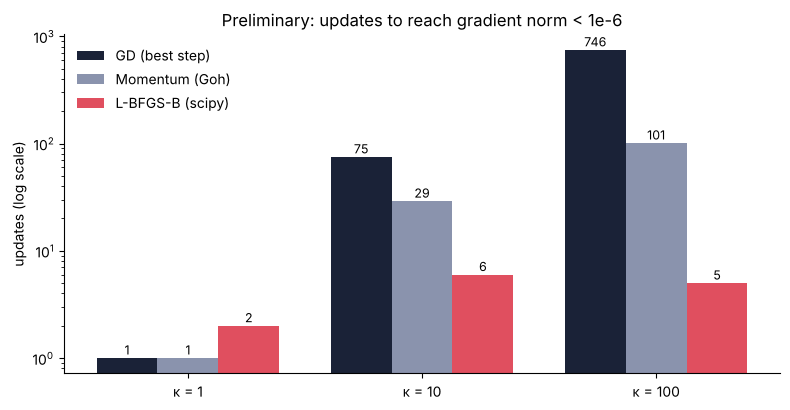

In [5]:
import matplotlib.pyplot as plt

labels = [f"κ = {k}" for k in others["kappa"]]
x = np.arange(len(labels))
w_bar = 0.26
series = [
    ("GD (best step)", others["GD updates (measured)"], "#1A2237"),
    ("Momentum (Goh)", others["momentum updates"], "#8A93AD"),
    ("L-BFGS-B (scipy)", others["L-BFGS-B iterations (scipy)"], "#E04F5F"),
]
fig, ax = plt.subplots(figsize=(8, 4.2))
for i, (name, vals, color) in enumerate(series):
    bars = ax.bar(x + (i - 1) * w_bar, vals, w_bar, label=name, color=color)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v * 1.08, f"{int(v)}", ha="center", fontsize=9)
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("updates (log scale)")
ax.set_title("Preliminary: updates to reach gradient norm < 1e-6")
ax.legend(frameon=False)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

## 7. What this shows, and what it does not

**Shows**
- The GD numbers on slide 3 (1, 75, 746) are reproduced by actually running GD, so the prediction formula holds on these datasets.
- GD's per-step error factor is 0, 0.82 and 0.98 at κ = 1, 10 and 100. This is the 0.98 on slide 2.
- In this quick check, momentum needs far fewer updates than GD at large κ, and L-BFGS needs only a handful at every κ.

**Does not show**
- It is not the official GD vs L-BFGS comparison. Counts depend on the line search and the stopping rule, which is why two L-BFGS variants are listed.
- These are noise-free, 2-weight, synthetic problems. The published instability of L-BFGS with noisy minibatches is a limit we do not test here.
- Muon is only discussed from its abstract, not run.

**Gap (slide 2).** In the studies we reviewed, κ changes together with dataset size, features and noise. Our datasets change κ alone (1, 10, 100) on noise-free data, so the effect of κ can be compared directly with theory.

| Slide 2 item | Where in this notebook |
|---|---|
| 0.98, 0.82, 0 per-step factors | Section 3 |
| κ = 1, 10, 100 datasets | Section 2 |
| Source list | Section 1 |